# Chapter 1
### From simple to multiple regression

```python
from statsmodels.formula.api import ols
mdl_mass_vs_length = ols('mass_g ~ length_cm', data = fish).fit() # one intercept + one slope
mdl_mass_vs_species = ols('mass_g ~ species + 0', data = fish).fit() # 4 coefficients, one per category
mdl_mass_vs_both = ols('mass_g ~ length_cm + species + 0', data = fish).fit() # 1 slope, 1 intercept per category
print(mdl_mass_vs_length.params)
sns.regplot(
    x = 'length_cm', 
    y = 'mass_g',
    data = fish,
    ci = None)
sns.boxplot(
    x = 'species',
    y = 'mass_g',
    data = fish,
    showmeans = True)
coeffs = mdl_mass_vs_both.params
ic_bream, ic_perch, ic_pike, ic_roach, sl = coeffs
sns.scatterplot(
    x = 'length_cm',
    y = 'mass_g',
    hue = 'species',
    data = fish)
for ic_fish, color in zip([ic_bream, ic_perch, ic_pike, ic_roach],['blue','green','red','orange']):
    plt.axline(xy1 = (0, ic_fish), slope = sl, color = color)
```

In [1]:
import numpy as np 
np.select

x = np.arange(6)
condlist = [x<3, x>3]
choicelist = [x, x**2]
print(condlist, choicelist)
np.select(condlist, choicelist, 42)

[array([ True,  True,  True, False, False, False]), array([False, False, False, False,  True,  True])] [array([0, 1, 2, 3, 4, 5]), array([ 0,  1,  4,  9, 16, 25])]


array([ 0,  1,  2, 42, 16, 25])

In [2]:
a = [[True,False,False],[True,True,False]]
b = [[1,2,3],[4,5,6]]

np.select(a,b,999)

array([  1,   5, 999])

# Chapter 2

- making predictions using two coefficients (one of them is categorical - this is shocking for me!)

```python

# part 1: generating prediction workflow - custom categorical & numerical values for explanatory variables
from itertools import product
length_com = np.arange(5,61,5)
species = fish['species'].unique()
p = product(length_cm, species) # could be [(l, s) for l in length_cm for s in species]
expl_data_both = pd.DataFrame(p, columns = ['length_cm','species'])
# predicting mass_g from only length & from length & species
prediction_data_length = expl_data_length.assign(mass_g = mdl_mass_vs_length.predict(expl_data))
prediction_data_both = expl_data_both.assign(mass_g = mdl_mass_vs_both.predict(expl_data))

# visualizing predictions
for ic, color in zip([ic_bream, ic_perch, ic_pike, ic_roach],['blue green red orange'.split()]):
    plt.axline(xy1 = (0, ic), slope = sl, color = color)

    sns.scatterplot(
    x = 'length_cm', 
    y = 'mass_g',
    hue = 'species',
    data = fish)
sns.scatterplot(
    x = 'length_cm',
    y = 'mass_g',
    color = 'black',
    data = prediction_data)

continue...
```

-672.2418658971376 blue
-713.2928594927796 green
-1089.4560527593503 red
-726.7777988598328 orange


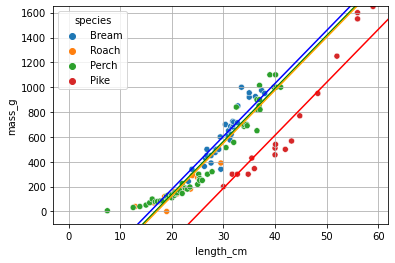

/home/user/.pyenv/versions/3.9.4/lib/python3.9/site-packages/seaborn/regression.py:592: UserWarning: legend_out is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


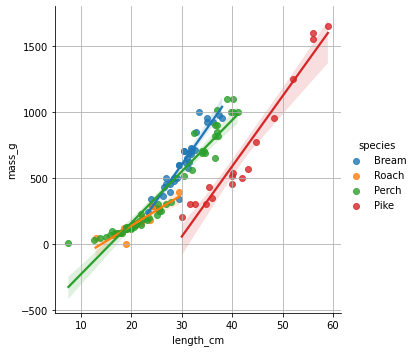

In [3]:
import pandas as pd
from statsmodels.formula.api import ols
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('fish.csv')

mdl = ols('mass_g ~ length_cm + species + 0', data = df).fit()

ic_bream, ic_perch, ic_pike, ic_roach, sl = mdl.params

for ic, color in zip([ic_bream, ic_perch, ic_pike, ic_roach],['blue','green','red','orange']):
    print(ic, color)
    plt.axline(xy1 = (0, ic), slope = sl, color = color)
sns.scatterplot(
    x = 'length_cm',
    y = 'mass_g',
    hue = 'species',
    data = df
)
sl
plt.ylim(-100, df['mass_g'].max())
plt.grid()
plt.show()

sns.lmplot(
    x = 'length_cm',
    y = 'mass_g',
    data = df,
    hue = 'species',
    legend_out = True
)
plt.grid()
plt.show()

<AxesSubplot:xlabel='length_cm', ylabel='mass_g'>

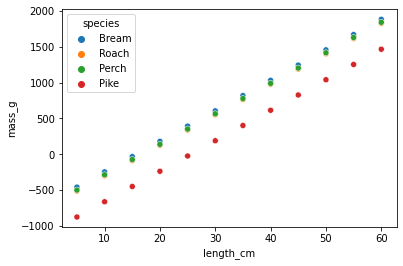

In [4]:
expl_data_both = pd.DataFrame(
    data = [[length, specie] for length in range(5,61,5) for specie in df['species'].unique()],
    columns = ['length_cm','species']
)

conditions = [expl_data_both['species'] == specie for specie in expl_data_both['species'].sort_values().unique()]
choices = [ic_bream, ic_perch, ic_pike, ic_roach]
intercept = np.select(conditions, choices)
prediction_data = expl_data_both.assign(intercept = intercept, mass_g = intercept + sl * expl_data_both['length_cm'])
prediction_data['mass_g_from_mdl'] = mdl.predict(expl_data_both)
prediction_data
sns.scatterplot(
x = 'length_cm',
    y = 'mass_g',
    hue = 'species',
    data = prediction_data
    )


#### Assessing model performance
- Coefficient of determination (R-squared)
  - larger is better
- Residual standard error (RSE):
  - smaller is better
  
```python
print(mdl_mass_vs_length.rsquared)
print(mdl_mass_vs_species.rsquared)
print(mdl_mass_vs_both.rsquared) # best result - but is that good?
```

- Adjusted Coefficient of Determination
  - too many explanatory variables causes overfitting
  - Adjusted coef of determination penalizes more explanatory variables
  - Ra2 = 1- (1-R2) * (n_obs - 1/)/(n_obs - n_var - 1)
  - in statsmodels:: rsquared_adj attribute
  
```python
print(mdl_mass_vs_both.rsquared)
print(mdl_mass_vs_both.rsquared_adj)
print(mdl_mass_vs_both.mse_resid)
rse_both = np.sqrt(mdl_mass_vs_both.mse_resid)
print(rse_both)
```
  


#### Specifying interactions

```python
# no interactions: response ~ explanatory1 + explanatory2
ols('mass_g ~ length_cm + species', data = df).fit() # one slope, 4 intercepts
# with interactions (implicit): response ~ explanatory1 * explanatory2
ols('mass_g ~ length_cm * species', data = df).fit() # mdl.params get ugly
# with interactions (explicit): response ~ explanatory1 + explanatory2 + explanatory1:explanatory2
ols('mass_g ~ length_cm + species + length_cm:species', data = df).fit() #mdl.params get perfect!
```

In [71]:
mdl_mass_vs_both_i = ols('mass_g ~ species + length_cm', data = df).fit() # 1 + 3 intercepts + 1 slope
mdl_mass_vs_both_i = ols('mass_g ~ species + length_cm + 0', data = df).fit() # 4 intercepts + 1 slope
mdl_mass_vs_both_i = ols('mass_g ~ species : length_cm', data = df).fit() # 1 intercept + 4 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species : length_cm + 0', data = df).fit() # 4 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + species:length_cm', data = df).fit() # 1 + 3 intercepts+ 4 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + species:length_cm + 0', data = df).fit() # 4 intercepts+ 4 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + length_cm + species:length_cm', data = df).fit() # 1+3 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + length_cm + species:length_cm + 0', data = df).fit() # 4 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species * length_cm', data = df).fit() # 1+3 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species * length_cm + 0', data = df).fit() # 4 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + species * length_cm', data = df).fit() # 1+3 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + length_cm + species * length_cm + 0', data = df).fit() # 4 intercepts + 1+3 slopes
mdl_mass_vs_both_i = ols('mass_g ~ species + species * length_cm + 0', data = df).fit() # 4 intercepts + 1+3 slopes


mdl_mass_vs_both_i.params

species[Bream]               -1035.347565
species[Perch]                -619.175114
species[Pike]                -1540.824272
species[Roach]                -329.376211
length_cm                       54.549981
species[T.Perch]:length_cm     -15.638514
species[T.Pike]:length_cm       -1.355115
species[T.Roach]:length_cm     -31.230717
dtype: float64

In [72]:
mdl_mass_vs_both_i.predict()

array([ 230.21199261,  273.85197736,  268.39697927,  399.31693351,
        410.2269297 ,  426.59192398,  426.59192398,  470.23190873,
        470.23190873,  519.32689157,  513.87189348,  530.23688776,
        552.05688013,  573.8768725 ,  568.42187441,  568.42187441,
        622.97185535,  622.97185535,  650.24684581,  655.70184391,
        672.06683819,  677.52183628,  682.97683437,  699.34182865,
        704.79682675,  699.34182865,  710.25182484,  748.4368115 ,
        753.89180959,  792.07679624,  873.90176765,  873.90176765,
        939.36174477, 1004.82172189, 1037.55171045,  -28.55770182,
         55.39164957,   78.71091385,   95.03439884,  104.36210456,
        113.68981027,  116.02173669,  123.01751598,  146.33678025,
        148.66870668,  148.66870668,  160.32833882,  162.66026525,
        183.64760309,  183.64760309,  185.97952952,  220.95842594,
        230.28613165,  253.60539592,  358.54208517, -327.33911102,
       -132.78177545,  -82.1968682 ,  -35.50310767,   -8.26508

In [11]:
df.shape

(128, 3)

# Chapter 3

```python
# scatterplot with color for response variable:
sns.scatterplot(
    x = 'length_cm',
    y = 'height_cm',
    data = fish,
    hue = 'mass_g')
# twho numeric explanatory variables: 1 intercept + 2 slopes
mdl_mass_vs_both = ols('mass_g ~ length_cm + height_cm', data = fish).fit()
print(mdl_mass_vs_both.params)
```

Prediction flow:
- create custom dataframe with all main possible explanatory variables possibilities
- predict response variable for each dataframe row
```python
from itertools import product
length_cm = np.arange(5,61,5)
height_cm = np.arange(2,21,2)
p = product(length_cm, height_cm)
exploratory_data = pd.DataFrame(p, columns = ['length_cm','height_cm'])
from statsmodels.formula.api import ols
mdl_model_vs_both = ols('mass_g ~ length_cm + height_cm', data = fish).fit()
prediction_data = explanatory_data.assign(mass_g = mdl_mass_vs_both.predict(explanatory_data))
```
Including an interaction:
- 1 intercept + 3 slopes (length_cm, height_cm, length_cm:height_cm)
```python
mdl_mass_vs_both_inter = ols('mass_g ~ length_cm * height_cm', data = fish).fit()
```

#### more than two explanatory variables

```python
grid = sns.FacetGrid(
    data = fish,
    col = 'species',
    hue = 'mass_g',
    col_wrap = 2,
    pallete = 'plasma'
    )
grid.map(
    sns.scatterplot,
    'length_cm',
    'height_cm')
plt.show()
```


two way interactions:
```python
ols('''mass_g ~ 
    length_cm + height_cm + species 
    + length_cm:height_cm 
    + length_cm:species
    + height_cm:species
    ''', data = fish).fit()
#or
ols('mass_g ~ (length_cm + height+com + species)**2', data = fish).fit()
```

three way interactions (all interactions):
```python
ols('''mass_g ~ 
    length_cm + height_cm + species 
    + length_cm:height_cm 
    + length_cm:species
    + height_cm:species
    + length_cm:height_cm:specis''', data = fish).fit()
#or
ols('mass_g ~ length_cm*height*cm*species', data = fish).fit()
    

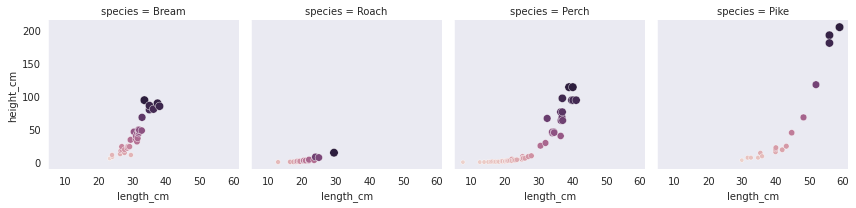

In [60]:
import seaborn as sns
import pandas as pd 
import numpy as np


np.random.seed(42)

df = pd.read_csv('fish.csv')
df['height_cm'] = (df['mass_g'] * df['mass_g'] * df['species'].str.len()) /20000*np.random.random()

# sns.set_style('dark')

grid = sns.FacetGrid(
    data = df.assign(lala = 1),
    col = 'species',
#     hue = 'mass_g',
#     col_wrap = 2,
    palette = 'plasma'
)
grid.map(sns.scatterplot,  'length_cm', 'height_cm', 'mass_g',  'mass_g')

# sns.scatterplot(
#         data = df,
#     x = 'length_cm',
#     y = 'height_cm',
#     size = 'mass_g'
# )

#### How to calculate linear regression from MSE:

```python
y = intercept + slope * x
df = pd.read_csv('fish.csv')

def calc_sum_of_squares(coeffs):
    """ returns the derivative; value where the sum of squares is minimal: 
    mse = min(mse), 
    being mse the sum of possible sum of squares
    """
    intercept, slope = coeffs
    residuals = y - (intercept + slope * x)
    mse = sum(residuals**2)
    return mse
```






In [68]:
from scipy.optimize import minimize

y = df['mass_g']
x = df['length_cm']

def lala(coeffs):
    intercept, slope = coeffs
    residuals = y - (intercept + slope * x)
    mse = sum(residuals**2)
    return mse

minimize(fun = lala, x0 = [0,0])
    

      fun: 2915737.8823462967
 hess_inv: array([[ 5.43167303e-02, -1.72849938e-03],
       [-1.72849938e-03,  5.93722874e-05]])
      jac: array([0.   , 0.125])
  message: 'Desired error not necessarily achieved due to precision loss.'
     nfev: 132
      nit: 6
     njev: 40
   status: 2
  success: False
        x: array([-536.2213009 ,   34.89916185])

In [74]:
from statsmodels.formula.api import ols
mdl = ols('mass_g ~ length_cm', data = df).fit()
mdl.params

Intercept   -536.223947
length_cm     34.899245
dtype: float64

In [72]:
from statsmodels.function.api import ols

ModuleNotFoundError: No module named 'statsmodels.function'

# Chapter 4

- gaussian curves (from scipy.stats import norm)
  - gaussian probability density function (norm.pdf)
  - Gaussian cumulative distribution function (norm.cdf)
  - gaussian inverse CDF (norm.ppf)
- logistic curve (from scipy.stats import logistic)
  - logistic PDF (logistic.pdf())
  - logistic cdf (logistic.cdf())
  - logistic distribution CDF (logistic.ppf)
- logistic distribution CDF is also called the logistic function
  - logistic function
  - cdf(x) = 1/(1+exp(-x))

- logistic distribution inverse CDF is also called the logit function
  - logistic.ppf()
  - logit function
  - inverse_cdf(p) = log(p/(1-p))
  - logit function = inverse logistic function = logistic distribution inverse cumulative distribution function
```python
from scipy.stats import norm
gauss_pdf = norm.pdf(x)
gauss_cdf = norm.cdf(x)
gauss_ppf = norm.ppf(x) # inverce cdf
from scipy.stats import logistic
logistic_dist = logistic.cdf(x) # generates sigmoid curve
logistic_pdf = norm.pdf(x)
logistic_ppf = norm.ppf(x)
```

- Normal distribution:
  - mean, standard deviation
- logistic distribution:
  - location, scale

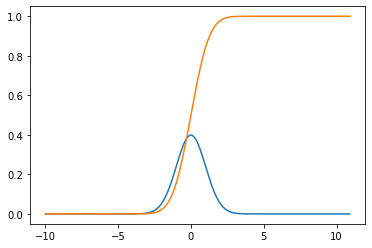

In [18]:
# probability distribution curve
from scipy.stats import norm
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(-10,11,.1)
yp = norm.pdf(x, loc = 0, scale = 1)
yc = norm.cdf(x, loc = 0, scale = 1)

plt.plot(x,yp)
plt.plot(x, yc)

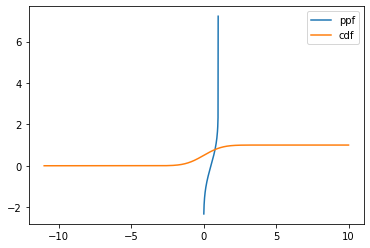

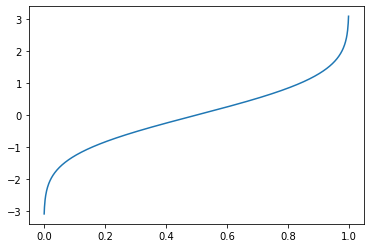

In [30]:
# percent point function
from scipy.stats import norm
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(-11,10,0.01)
y_ppf =  norm.ppf(x, loc = 0, scale = 1)
y_cdf = norm.cdf(x, loc = 0, scale = 1)

plt.plot(x,y_ppf, label = 'ppf')
plt.plot(x, y_cdf, label = 'cdf')
plt.legend()
plt.show()

# ppf: starts at zero(minimal % possiblility) and ends at 1 (maximal % possibility)
x = np.arange(-0,1.2,0.001)
y = norm.ppf(x)
plt.plot(x,y)

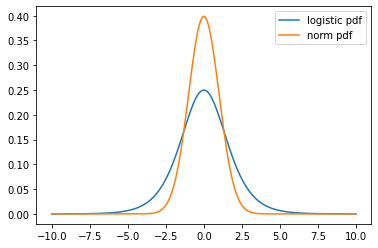

In [33]:
# logistic pdf: normal cdf with larger tail
from scipy.stats import logistic, norm

x = np.arange(-10,10.1,.1)
yl = logistic.pdf(x, loc = 0, scale = 1)
yn = norm.pdf(x, loc = 0, scale = 1)
plt.plot(x,yl, label = 'logistic pdf')
plt.plot(x, yn, label = 'norm pdf')
plt.legend()
plt.show()

<AxesSubplot:xlabel='x', ylabel='log_cdf'>

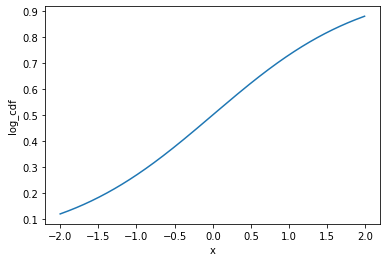

In [51]:
# logistic distribution inverse CDF: logit function
from scipy.stats import logistic, norm
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 


x = np.arange(-2,2,0.01)
df = pd.DataFrame(
    {
        'x':x,
        'pdf':norm.pdf(x),
        'pdf_man':np.exp((-x**2)/2)/np.sqrt(2*np.pi),
        'log_cdf':logistic.cdf(x),
        'log_cdf_man': 1/(1 + np.exp(-x)),
        
    }
)
sns.lineplot(
x = 'x', y = 'log_cdf', data = df)

#### Logistic regression

```python
# sum of squares doesn't work
sum(np.sum(y_pred - y_actual)**2) # does not work

# this one works (why???)
y_pred * y_actual + (1 - y_pred) * (1 - y_actual)
likelihood = sum(y_pred * y_actual + 1 - y_actual - y_pred + y_pred * y_actual) # not so good
log_likelihood = sum(np.log(y_pred) * y_actual + np.log(1 - y_pred) * (1 - y_actual)) # gives same answer, but better values

# tweak: use this
- log_likelihood

def calc_neg_log_likelihood(coeffs):
    intercept,slope = coeffs
    y_pred = logistic.cdf(intercept + slope * x)
    #or
    y_pred = 1/(1 + exp(-x))
    log_likelihood = ...
    return log_likelihood

from scipy.optimize import minimize

minimize(fun = calc_neg_log_likelihood, x0 = [0,0])
```



In [46]:
norm.cdf?

In [91]:
from scipy.optimize import minimize


df = pd.read_csv('fish.csv')
df['is_bream'] = np.where(df['species'] == 'Bream',1,0)
from statsmodels.formula.api import logit
mod_log = logit('is_bream ~ mass_g', data = df).fit()
df['pred'] = mod_log.predict()

y_actual = df['is_bream']
x_actual = df['mass_g']

def man_logit(coeffs):
    intercept, slope = coeffs
    y_pred = logistic.cdf(intercept + slope * x_actual)
    log_likelihood = np.log(y_pred) * y_actual + np.log(1 - y_pred) * (1 - y_actual)
    neg_sum_ll = -np.sum(log_likelihood)
    return neg_sum_ll


man_logit((0,1))
x = minimize(fun = man_logit, x0 = [0,0])
print(np.isclose(x['x'], mod_log.params))

df['pred_man'] = logistic.cdf(x['x'][0] + df['mass_g'] * x['x'][1] )
df

Optimization terminated successfully.
         Current function value: 0.549393
         Iterations 5


/tmp/ipykernel_4680/175200710.py:16: RuntimeWarning: divide by zero encountered in log
  log_likelihood = np.log(y_pred) * y_actual + np.log(1 - y_pred) * (1 - y_actual)
/home/user/.pyenv/versions/3.9.4/lib/python3.9/site-packages/scipy/optimize/_numdiff.py:576: RuntimeWarning: invalid value encountered in subtract
  df = fun(x) - f0
/tmp/ipykernel_4680/175200710.py:16: RuntimeWarning: divide by zero encountered in log
  log_likelihood = np.log(y_pred) * y_actual + np.log(1 - y_pred) * (1 - y_actual)


[ True  True]


,species,mass_g,length_cm,is_bream,pred,pred_man
0,Bream,242.0,23.2,1,0.196509,0.196510
1,Bream,290.0,24.0,1,0.209649,0.209650
2,Bream,340.0,23.9,1,0.224012,0.224012
3,Bream,363.0,26.3,1,0.230849,0.230850
4,Bream,430.0,26.5,1,0.251588,0.251589
...,...,...,...,...,...,...
123,Pike,950.0,48.3,0,0.447616,0.447613
124,Pike,1250.0,52.0,0,0.573782,0.573778
125,Pike,1600.0,56.0,0,0.708788,0.708783
126,Pike,1550.0,56.0,0,0.691022,0.691017


In [92]:
# to understand logistic regression, one must know:
# normal distribution
# cumulative normal distribution
# log
# logistic cumulative normal distribution

# Next:
- train test sets
- cross validation
- P-values and significance